# 🥛 Monthly Milk Production Forecasting
### Using RNN, LSTM and GRU Deep Learning Models

---

## Step 1 · Business Problem

The file `monthly_milk_production.csv` contains the **monthly milk production** of a dairy farm / industry (Jan 1962 – Dec 1975, 168 observations).

The business needs to **forecast future milk production** in order to:

- plan the **supply chain and distribution** properly,
- manage **inventory and storage** efficiently,
- optimise **workforce and operational activities** around expected production levels,
- take **strategic decisions** about scaling production or handling seasonal fluctuations.

## Step 2 · Objective

> *Develop a time-series forecasting model that accurately predicts monthly milk production for the upcoming months, so the dairy business can make informed operational and strategic decisions, minimise waste and meet market demand effectively.*

## Notebook roadmap

| # | Section | What we do |
|---|---------|-----------|
| 1 | Exploratory Data Analysis | trend, seasonality, anomalies, missing values, outliers |
| 2 | Data Preparation | scaling, windowing, train / validation / test split, reshaping |
| 3 | Model Building | Simple RNN, LSTM, GRU + hyper-parameter tuning |
| 4 | Model Evaluation | predictions vs actuals, RMSE / MAE / MAPE, model comparison |
| 5 | Forecast | next 12 months with an uncertainty band |
| 6 | Business Insights | interpretation and recommendations |

## 0 · Setup

Import the libraries, fix the random seeds (so the notebook is **reproducible**) and define a small colour palette that is used consistently across all plots
(one fixed colour per entity: *Actual* = dark grey, *RNN* = blue, *LSTM* = orange, *GRU* = aqua).

In [1]:
import os, time, warnings, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # keep TensorFlow logs quiet
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates

from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow.keras import Sequential, layers, callbacks, optimizers

# ---- Reproducibility ----------------------------------------------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")                 # silence tf.function retracing warnings

# ---- Plot styling (thin lines, recessive grid, fixed colour per entity) --------------
COLORS = {"Actual": "#3d3d3a", "RNN": "#2a78d6", "LSTM": "#eb6834", "GRU": "#1baf7a",
          "Baseline": "#8a8985", "Forecast": "#6250d6"}
mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#b9b8b3", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 1.8, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("TensorFlow", tf.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

I0000 00:00:1792816948.103553   28807 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792816951.129658   28807 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | pandas 3.0.5 | numpy 2.5.3


---
# 1 · Exploratory Data Analysis (EDA)

## 1.1 Load and inspect the data
The `Date` column is stored as text (`YYYY-MM`). We parse it to a proper monthly `DatetimeIndex` so time-series tools work correctly.

In [2]:
# Load the CSV and convert 'Date' into a monthly DatetimeIndex
df = pd.read_csv("monthly_milk_production.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m")
df = df.set_index("Date").sort_index()

print("Shape               :", df.shape)
print("Period covered      :", df.index.min().strftime("%b %Y"), "->", df.index.max().strftime("%b %Y"))
print("Data types          :", dict(df.dtypes.astype(str)))
display(df.head())
display(df.tail())

Shape               : (168, 1)
Period covered      : Jan 1962 -> Dec 1975
Data types          : {'Production': 'int64'}


,Production
Date,
1962-01-01,589
1962-02-01,561
1962-03-01,640
1962-04-01,656
1962-05-01,727


,Production
Date,
1975-08-01,858
1975-09-01,817
1975-10-01,827
1975-11-01,797
1975-12-01,843


## 1.2 Data-quality checks: missing values, duplicates, gaps and outliers
Before modelling we make sure the series is **complete** (no missing months), has **no duplicated dates** and no impossible values.

In [3]:
# ---- Missing values, duplicates, continuity -------------------------------------------
full_range = pd.date_range(df.index.min(), df.index.max(), freq="MS")
print("Missing values in 'Production' :", int(df["Production"].isna().sum()))
print("Duplicated dates               :", int(df.index.duplicated().sum()))
print("Missing months in the calendar :", len(full_range.difference(df.index)))
print("Non-positive values            :", int((df["Production"] <= 0).sum()))

# Make the monthly frequency explicit (it is already complete, so nothing is added)
df = df.asfreq("MS")
series = df["Production"].astype(float)

print("\nSummary statistics")
display(series.describe().to_frame("Production").T)

Missing values in 'Production' : 0
Duplicated dates               : 0
Missing months in the calendar : 0
Non-positive values            : 0

Summary statistics


,count,mean,std,min,25%,50%,75%,max
Production,168.00,754.71,102.20,553.00,677.75,761.00,824.50,969.00


## 1.3 Visualise the trend

The raw series is plotted together with a **12-month rolling mean**, which averages out the seasonal cycle and exposes the underlying trend.

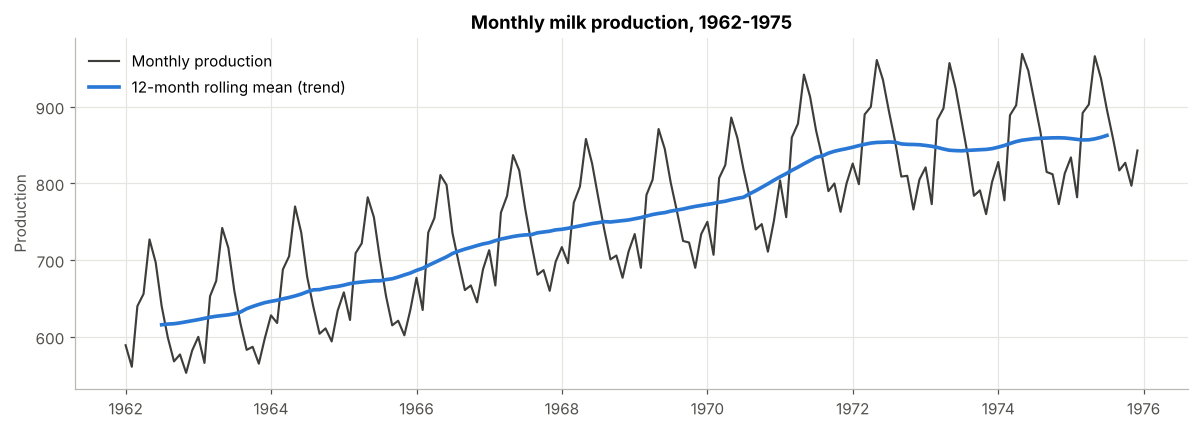

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(series.index, series, color=COLORS["Actual"], lw=1.4, label="Monthly production")
ax.plot(series.rolling(12, center=True).mean(), color=COLORS["RNN"], lw=2.4, label="12-month rolling mean (trend)")
ax.set_title("Monthly milk production, 1962-1975")
ax.set_ylabel("Production"); ax.set_xlabel("")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 1.4 Visualise the seasonality

Three complementary views:

1. **Annual average** – shows the long-term trend year by year.
2. **Average by calendar month** – shows the typical seasonal shape.
3. **Seasonal plot** – one line per year (light → dark = early → late years) to check the pattern is stable over time.

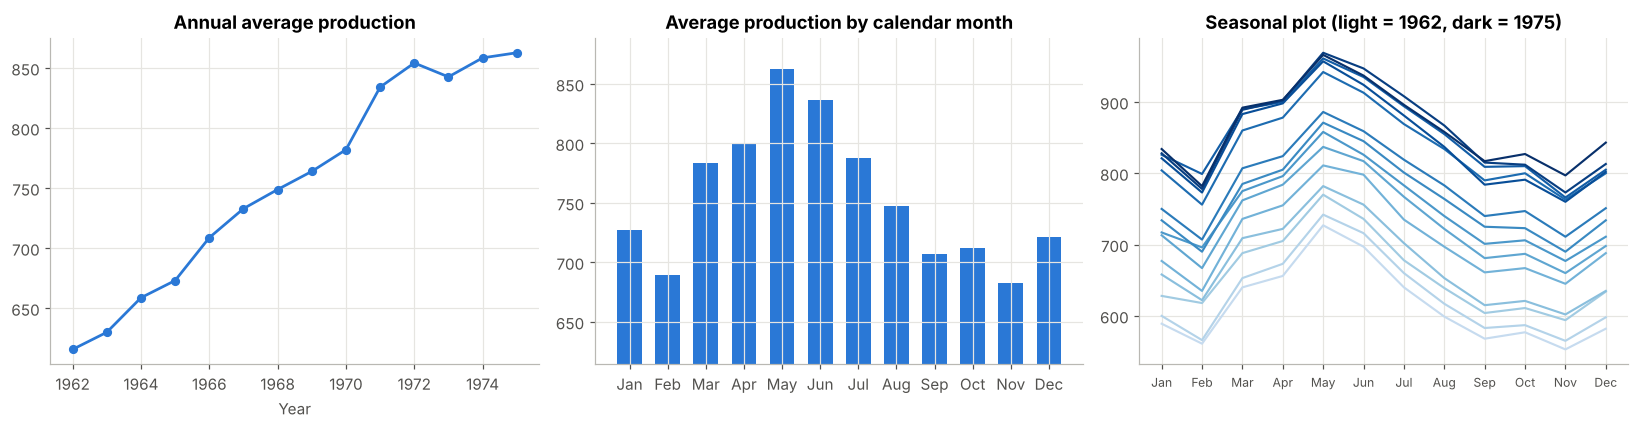

Peak month   : May (avg 863)
Lowest month : Nov (avg 683)
Annual average rose from 616 (1962) to 863 (1975)


In [5]:
annual_mean   = series.resample("YS").mean()
monthly_shape = series.groupby(series.index.month).mean()
month_names   = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (1) annual average -> trend
axes[0].plot(annual_mean.index.year, annual_mean.values, marker="o", ms=5, color=COLORS["RNN"])
axes[0].set_title("Annual average production"); axes[0].set_xlabel("Year")

# (2) average by calendar month -> seasonal shape
axes[1].bar(month_names, monthly_shape.values, color=COLORS["RNN"], width=0.65)
axes[1].set_ylim(monthly_shape.min() * 0.9, monthly_shape.max() * 1.03)
axes[1].set_title("Average production by calendar month")

# (3) seasonal plot, one line per year (single-hue sequential colouring)
years = sorted(series.index.year.unique())
cmap  = plt.get_cmap("Blues")
for i, y in enumerate(years):
    s = series[series.index.year == y]
    axes[2].plot(s.index.month, s.values, color=cmap(0.25 + 0.75 * i / (len(years) - 1)), lw=1.4)
axes[2].set_xticks(range(1, 13)); axes[2].set_xticklabels(month_names, fontsize=8)
axes[2].set_title("Seasonal plot (light = 1962, dark = 1975)")
plt.tight_layout(); plt.show()

print("Peak month   :", month_names[monthly_shape.idxmax() - 1], f"(avg {monthly_shape.max():.0f})")
print("Lowest month :", month_names[monthly_shape.idxmin() - 1], f"(avg {monthly_shape.min():.0f})")
print(f"Annual average rose from {annual_mean.iloc[0]:.0f} (1962) to {annual_mean.iloc[-1]:.0f} (1975)")

## 1.5 Decompose into trend, seasonality and residual

We use **STL decomposition** (robust version, 12-month period). The *residual* component is what is left after removing trend and seasonality, which makes it ideal for **anomaly / outlier detection**.

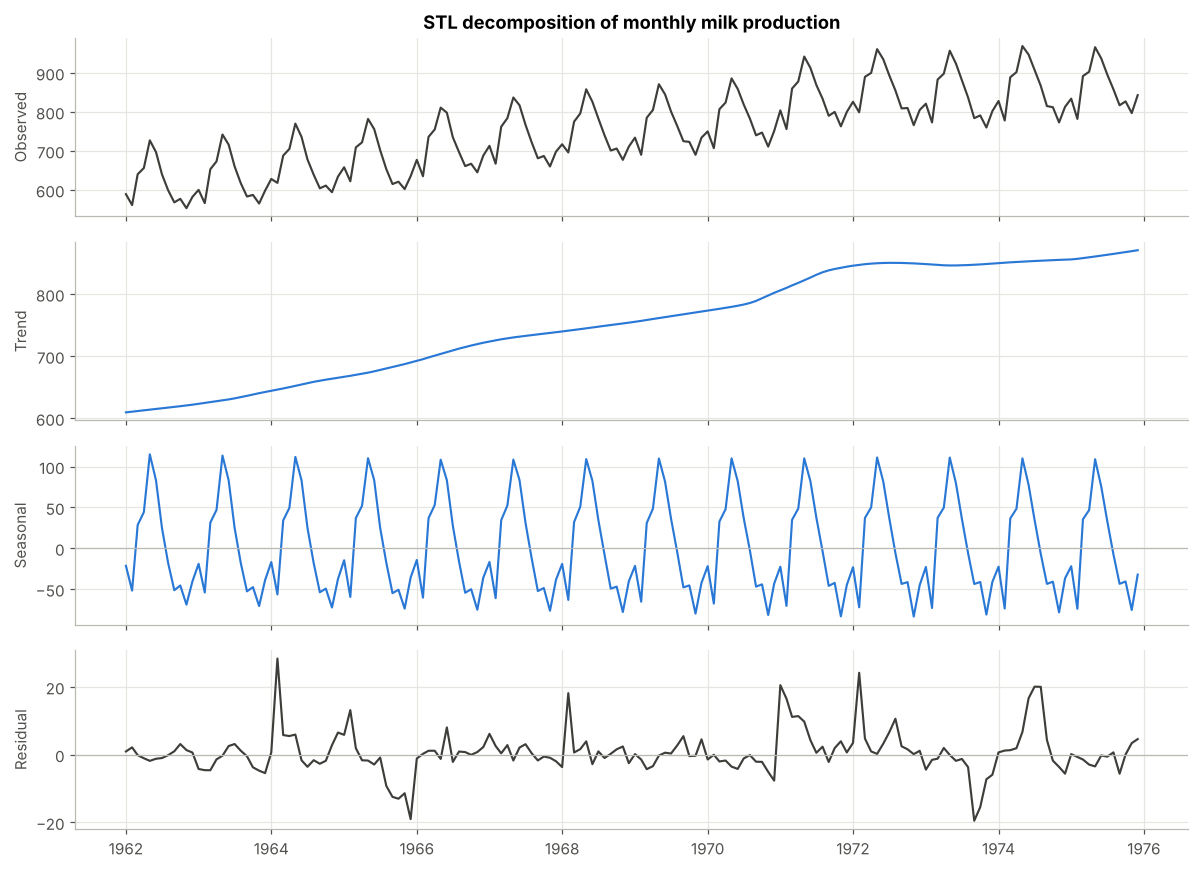

Strength of seasonality : 0.99  (0 = none, 1 = very strong)
Strength of trend       : 0.99


In [6]:
stl = STL(series, period=12, robust=True).fit()

parts  = [("Observed", series), ("Trend", stl.trend), ("Seasonal", stl.seasonal), ("Residual", stl.resid)]
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, (name, s) in zip(axes, parts):
    ax.plot(s.index, s.values, color=COLORS["Actual"] if name in ("Observed", "Residual") else COLORS["RNN"], lw=1.4)
    ax.set_ylabel(name)
axes[2].axhline(0, color="#b9b8b3", lw=0.8); axes[3].axhline(0, color="#b9b8b3", lw=0.8)
axes[0].set_title("STL decomposition of monthly milk production")
plt.tight_layout(); plt.show()

seasonal_strength = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
trend_strength    = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())
print(f"Strength of seasonality : {seasonal_strength:.2f}  (0 = none, 1 = very strong)")
print(f"Strength of trend       : {trend_strength:.2f}")

## 1.6 Outlier / anomaly detection

Two standard rules are applied to the **STL residuals** (so that normal seasonal peaks are *not* mistaken for anomalies):

- **IQR rule** – flag points outside `Q1 − 1.5·IQR` and `Q3 + 1.5·IQR`
- **Z-score rule** – flag points with `|z| > 3`

IQR bounds on residuals : [-8.2, 8.8]
Outliers by IQR rule    : 20
Outliers by Z-score rule: 7


,Production,Residual,Z-score
Date,,,
1964-02-01,618.00,28.37,4.30
1965-02-01,622.00,13.16,1.93
1965-08-01,653.00,-9.25,-1.55
1965-09-01,615.00,-12.46,-2.05
1965-10-01,621.00,-13.00,-2.14
1965-11-01,602.00,-11.39,-1.89
1965-12-01,635.00,-19.02,-3.07
1968-02-01,696.00,18.15,2.71
1971-01-01,804.00,20.52,3.08


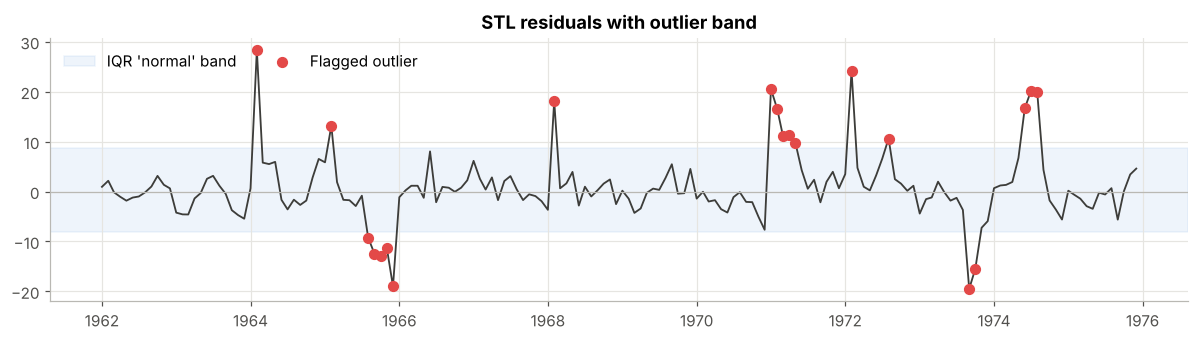

In [7]:
resid = stl.resid
q1, q3 = resid.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
z = (resid - resid.mean()) / resid.std()

iqr_out = resid[(resid < lo) | (resid > hi)]
z_out   = resid[z.abs() > 3]
print(f"IQR bounds on residuals : [{lo:.1f}, {hi:.1f}]")
print(f"Outliers by IQR rule    : {len(iqr_out)}")
print(f"Outliers by Z-score rule: {len(z_out)}")
if len(iqr_out):
    display(pd.DataFrame({"Production": series[iqr_out.index], "Residual": iqr_out, "Z-score": z[iqr_out.index]}))

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(resid.index, resid, color=COLORS["Actual"], lw=1.2)
ax.axhspan(lo, hi, color=COLORS["RNN"], alpha=0.08, label="IQR 'normal' band")
if len(iqr_out):
    ax.scatter(iqr_out.index, iqr_out, color="#e34948", s=40, zorder=3, label="Flagged outlier")
ax.axhline(0, color="#b9b8b3", lw=0.8)
ax.set_title("STL residuals with outlier band"); ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

## 1.7 Autocorrelation

The ACF shows how strongly the series is related to its own past. Large spikes at lags 12, 24, 36… confirm a **yearly seasonal cycle**, and slowly decaying values confirm the **trend**. This also guides the choice of the **window size** (how many past months the network should look at).

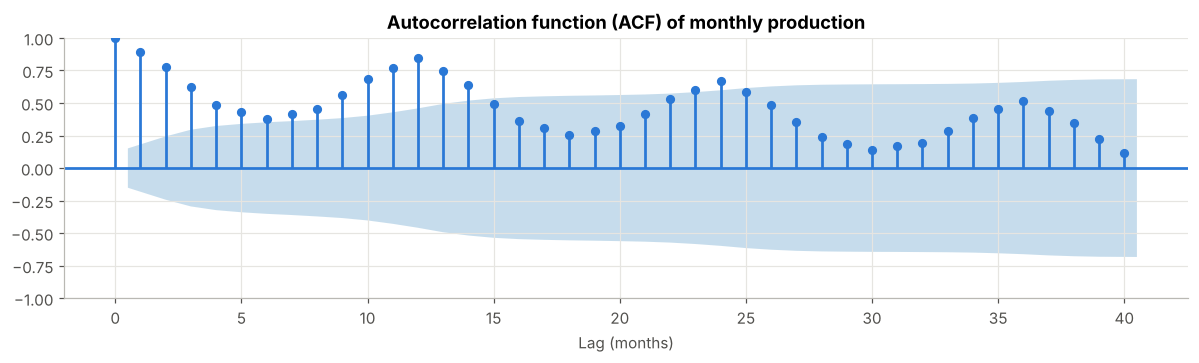

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.4))
plot_acf(series, lags=40, ax=ax, color=COLORS["RNN"], vlines_kwargs={"colors": COLORS["RNN"]})
ax.set_title("Autocorrelation function (ACF) of monthly production"); ax.set_xlabel("Lag (months)")
plt.tight_layout(); plt.show()

### 📌 EDA findings

- **Data quality:** 168 consecutive months, **no missing values, no duplicates, no gaps**, no impossible values – no cleaning was required.
- **Trend:** strong, steady growth – the annual average rose from **≈616 (1962) to ≈863 (1975)** (+40 %). Growth was fastest in 1965-1971 and has **flattened since 1972** (≈843-863 per year).
- **Seasonality:** very strong and stable yearly cycle. Production peaks in **May** (avg ≈863) and bottoms out in **November** (avg ≈683) – the peak month is about **26 % above** the low month. February is a short-month dip. STL gives a seasonal strength and trend strength of **0.99** each, i.e. almost all variation is explained by trend + season.
- **Anomalies / outliers:** after removing trend and season the residuals are tiny (a few units). The IQR rule is very strict on such small residuals and flags 20 months, but only 7 months exceed |z| > 3, the largest being **Feb 1964 (+28, z ≈ 4.3)** – less than 5 % of that month's level. These are mild, plausible fluctuations (not data errors), so **no values were removed or altered**.
- **ACF:** large autocorrelation at lags 12, 24, 36 confirms the annual cycle, so a window of **12 – 24 months** (one to two full cycles) is a sensible range for the networks.
- **Scaling:** Min-Max scaling to [0, 1], fitted on the training period only.

---
# 2 · Data Preparation for Deep Learning

## 2.1 Chronological train / validation / test split

Time-series data must be split **in time order** (never shuffled) so the model is always evaluated on data that lies *after* the data it was trained on.

| Split | Period | Months | Purpose |
|-------|--------|:------:|---------|
| **Train** | Jan 1962 – Dec 1971 | 120 | fit the network weights |
| **Validation** | Jan 1972 – Dec 1973 | 24 | tune hyper-parameters, early stopping |
| **Test** | Jan 1974 – Dec 1975 | 24 | final, untouched evaluation |

,Start,End,Months
Train,Jan 1962,Dec 1971,120
Validation,Jan 1972,Dec 1973,24
Test,Jan 1974,Dec 1975,24


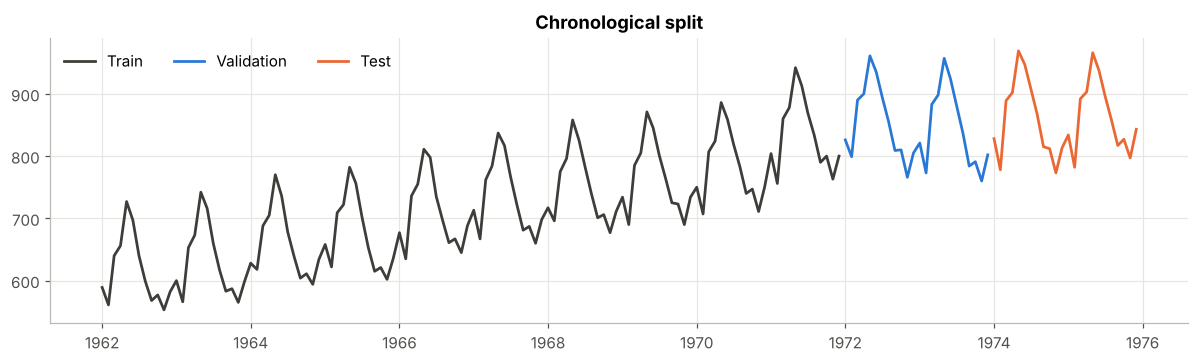

In [9]:
N          = len(series)          # 168 months
TRAIN_END  = 120                  # first 120 months  -> train
VAL_END    = 144                  # next 24 months    -> validation, last 24 -> test

train_s, val_s, test_s = series.iloc[:TRAIN_END], series.iloc[TRAIN_END:VAL_END], series.iloc[VAL_END:]
split_table = pd.DataFrame({
    "Start": [s.index[0].strftime("%b %Y") for s in (train_s, val_s, test_s)],
    "End":   [s.index[-1].strftime("%b %Y") for s in (train_s, val_s, test_s)],
    "Months": [len(train_s), len(val_s), len(test_s)],
}, index=["Train", "Validation", "Test"])
display(split_table)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(train_s, color=COLORS["Actual"], label="Train")
ax.plot(val_s,   color=COLORS["RNN"],    label="Validation")
ax.plot(test_s,  color=COLORS["LSTM"],   label="Test")
ax.set_title("Chronological split"); ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

## 2.2 Scaling

Neural networks train much better on small, well-scaled inputs. We apply **Min-Max scaling to the range [0, 1]**.

⚠️ The scaler is **fitted on the training data only** and then applied to validation and test data – otherwise information from the future would leak into training.

In [10]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_s.values.reshape(-1, 1))                      # fit on TRAIN only (no leakage)
scaled = scaler.transform(series.values.reshape(-1, 1)).ravel()  # transform the whole series

def inverse(x):
    # Convert scaled values back to the original production units
    return scaler.inverse_transform(np.asarray(x).reshape(-1, 1)).ravel()

print(f"Train min/max used by the scaler : {train_s.min():.0f} / {train_s.max():.0f}")
print(f"Scaled train range               : {scaled[:TRAIN_END].min():.2f} - {scaled[:TRAIN_END].max():.2f}")
print(f"Scaled test range                : {scaled[VAL_END:].min():.2f} - {scaled[VAL_END:].max():.2f}  (can exceed 1 because of the upward trend)")

Train min/max used by the scaler : 553 / 942
Scaled train range               : 0.00 - 1.00
Scaled test range                : 0.57 - 1.07  (can exceed 1 because of the upward trend)


## 2.3 Create input → output sequences (sliding windows)

Recurrent networks need supervised samples of the form

> **X** = the last *W* months  →  **y** = the next month

`make_sequences` builds these windows. For a target month `t`, the input is `series[t-W : t]`.
Validation / test windows may look back into the *previous* split for their inputs (these are past values, so there is no leakage), but their **targets** always lie inside their own split.

## 2.4 Reshape for the network

Keras recurrent layers expect a 3-D array: **(samples, time-steps, features)**. Here `features = 1` (only production is used).

In [11]:
def make_sequences(values, window, first_target, last_target):
    # Build (X, y) pairs for target indices in [first_target, last_target).
    # X has shape (samples, window, 1) -> ready for RNN / LSTM / GRU layers.
    X, y = [], []
    for t in range(first_target, last_target):
        X.append(values[t - window:t])
        y.append(values[t])
    X = np.array(X).reshape(-1, window, 1)       # (samples, time-steps, features)
    return X, np.array(y)

def get_splits(window):
    # Return train / validation / test sequences for a given window size.
    X_tr, y_tr = make_sequences(scaled, window, window,    TRAIN_END)
    X_va, y_va = make_sequences(scaled, window, TRAIN_END, VAL_END)
    X_te, y_te = make_sequences(scaled, window, VAL_END,   N)
    return X_tr, y_tr, X_va, y_va, X_te, y_te

# Quick look at the shapes for the two window sizes we will tune
for w in (12, 24):
    X_tr, y_tr, X_va, y_va, X_te, y_te = get_splits(w)
    print(f"window={w:>2} | train X{X_tr.shape} y{y_tr.shape} | val X{X_va.shape} | test X{X_te.shape}")

window=12 | train X(108, 12, 1) y(108,) | val X(24, 12, 1) | test X(24, 12, 1)
window=24 | train X(96, 24, 1) y(96,) | val X(24, 24, 1) | test X(24, 24, 1)


---
# 3 · Model Building

We build **three separate recurrent models** that share the same simple architecture so the comparison is fair:

```
Input (window, 1)  →  [ SimpleRNN | LSTM | GRU ] (units)  →  Dropout(0.1)  →  Dense(1)
```

| Choice | Setting | Why |
|--------|---------|-----|
| Loss | **Mean Squared Error** | standard for regression; penalises large misses |
| Optimiser | **Adam** (lr = 0.005) | adaptive, fast and robust for small recurrent nets |
| Regularisation | Dropout 0.1 + **Early Stopping** (patience 30, restore best weights) + ReduceLROnPlateau | small dataset → avoid over-fitting; also selects the *number of epochs* automatically |

**Hyper-parameter tuning** (grid search, scored by **validation RMSE** in original units):

- window size ∈ {12, 24} months
- hidden units ∈ {16, 32, 64}
- batch size ∈ {8, 16}
- epochs: up to 300, chosen automatically by early stopping

In [12]:
MODEL_LAYERS = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}
LEARNING_RATE, MAX_EPOCHS, PATIENCE = 0.005, 300, 30

def build_model(kind, window, units, lr=LEARNING_RATE):
    # Create one compiled recurrent model ('RNN', 'LSTM' or 'GRU').
    model = Sequential([
        layers.Input(shape=(window, 1)),
        MODEL_LAYERS[kind](units),            # the recurrent layer being compared
        layers.Dropout(0.1),                  # light regularisation
        layers.Dense(1),                      # next-month production (scaled)
    ], name=f"{kind}_w{window}_u{units}")
    model.compile(optimizer=optimizers.Adam(learning_rate=lr), loss="mse")
    return model

def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))

def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)

def all_metrics(y_true, y_pred):
    return {"RMSE": rmse(y_true, y_pred), "MAE": mae(y_true, y_pred), "MAPE (%)": mape(y_true, y_pred)}

# Show the architecture once
build_model("LSTM", 12, 32).summary()

Model: "LSTM_w12_u32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

## 3.1 Training helper

`fit_model` trains one configuration with early stopping on the validation loss and returns the fitted model, its history and the **best epoch** (needed later to re-train on all data without a validation set).

In [13]:
def fit_model(kind, window, units, batch_size, seed=SEED, verbose=0):
    # Train one configuration; the validation set drives early stopping.
    tf.keras.utils.set_random_seed(seed)
    X_tr, y_tr, X_va, y_va, *_ = get_splits(window)
    model = build_model(kind, window, units)
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-4)]
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=MAX_EPOCHS,
                     batch_size=batch_size, callbacks=cbs, shuffle=False, verbose=verbose)
    best_epoch = int(np.argmin(hist.history["val_loss"]) + 1)
    return model, hist, best_epoch

def val_rmse_original(model, window):
    # Validation RMSE in the ORIGINAL production units (comparable across window sizes).
    _, _, X_va, y_va, *_ = get_splits(window)
    pred = inverse(model.predict(X_va, verbose=0).ravel())
    return rmse(inverse(y_va), pred)

## 3.2 Hyper-parameter grid search

Every combination is trained for each of the three architectures (3 × 12 = 36 runs). The best model per architecture (lowest **validation** RMSE) is kept.
The test set is **not** touched here.

In [14]:
GRID = [(w, u, b) for w in (12, 24) for u in (16, 32, 64) for b in (8, 16)]
tuning_rows, best = [], {}

t0 = time.time()
for kind in ("RNN", "LSTM", "GRU"):
    for (w, u, b) in GRID:
        model, hist, best_ep = fit_model(kind, w, u, b)
        v = val_rmse_original(model, w)
        tuning_rows.append({"Model": kind, "Window": w, "Units": u, "Batch": b,
                            "Best epoch": best_ep, "Val RMSE": v})
        if kind not in best or v < best[kind]["val_rmse"]:
            best[kind] = dict(model=model, hist=hist, window=w, units=u, batch=b,
                              best_epoch=best_ep, val_rmse=v)
    print(f"{kind:<5} done | best: window={best[kind]['window']}, units={best[kind]['units']}, "
          f"batch={best[kind]['batch']}, epochs={best[kind]['best_epoch']}, val RMSE={best[kind]['val_rmse']:.2f}")
print(f"\nTotal tuning time: {(time.time() - t0) / 60:.1f} min")

tuning = pd.DataFrame(tuning_rows)

RNN   done | best: window=24, units=64, batch=8, epochs=101, val RMSE=10.37


LSTM  done | best: window=24, units=64, batch=16, epochs=44, val RMSE=24.41


GRU   done | best: window=24, units=64, batch=8, epochs=66, val RMSE=17.98

Total tuning time: 8.1 min


### Tuning results

Top 5 configurations per model (sorted by validation RMSE) and the overall best setting for each architecture.

In [15]:
for kind in ("RNN", "LSTM", "GRU"):
    print(f"\n{kind} - top 5 configurations")
    display(tuning[tuning.Model == kind].sort_values("Val RMSE").head(5).reset_index(drop=True))

best_cfg = pd.DataFrame({k: {"Window": v["window"], "Units": v["units"], "Batch": v["batch"],
                             "Epochs (early-stopped)": v["best_epoch"], "Val RMSE": v["val_rmse"]}
                         for k, v in best.items()}).T
print("\nSelected hyper-parameters")
display(best_cfg)


RNN - top 5 configurations


,Model,Window,Units,Batch,Best epoch,Val RMSE
0,RNN,24,64,8,101,10.37
1,RNN,24,64,16,67,12.19
2,RNN,24,32,16,77,13.38
3,RNN,24,32,8,83,13.42
4,RNN,24,16,8,77,15.90



LSTM - top 5 configurations


,Model,Window,Units,Batch,Best epoch,Val RMSE
0,LSTM,24,64,16,44,24.41
1,LSTM,24,64,8,48,24.56
2,LSTM,12,32,16,37,25.80
3,LSTM,24,32,8,35,25.92
4,LSTM,12,64,8,39,26.21



GRU - top 5 configurations


,Model,Window,Units,Batch,Best epoch,Val RMSE
0,GRU,24,64,8,66,17.98
1,GRU,12,64,16,86,18.84
2,GRU,12,32,8,86,19.50
3,GRU,24,64,16,115,20.27
4,GRU,12,64,8,47,20.31



Selected hyper-parameters


,Window,Units,Batch,Epochs (early-stopped),Val RMSE
RNN,24.00,64.00,8.00,101.00,10.37
LSTM,24.00,64.00,16.00,44.00,24.41
GRU,24.00,64.00,8.00,66.00,17.98


### Training curves of the selected models

Training and validation loss (MSE on scaled data) should both fall and stay close together; a widening gap would signal over-fitting.

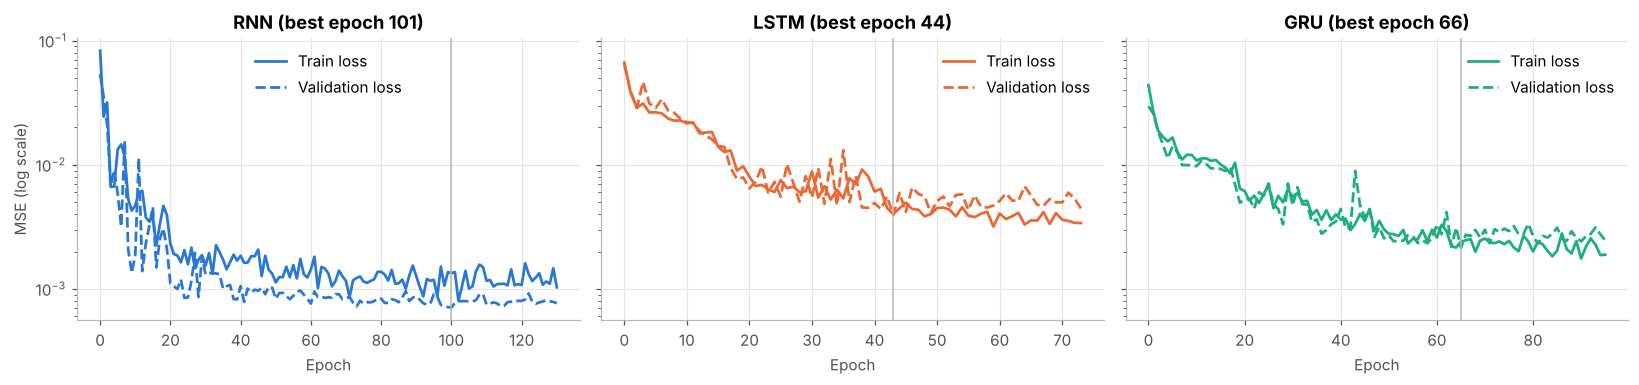

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, kind in zip(axes, ("RNN", "LSTM", "GRU")):
    h = best[kind]["hist"].history
    ax.plot(h["loss"],     color=COLORS[kind], label="Train loss")
    ax.plot(h["val_loss"], color=COLORS[kind], ls="--", label="Validation loss")
    ax.axvline(best[kind]["best_epoch"] - 1, color="#b9b8b3", lw=1)
    ax.set_yscale("log"); ax.set_title(f"{kind} (best epoch {best[kind]['best_epoch']})"); ax.set_xlabel("Epoch")
    ax.legend()
axes[0].set_ylabel("MSE (log scale)")
plt.tight_layout(); plt.show()

---
# 4 · Model Evaluation

We evaluate on the **untouched test set (1974-1975)** in two ways:

1. **One-step-ahead forecast** – each test month is predicted from the *actual* previous months (how the model performs when fresh data arrives every month).
2. **12-month recursive back-test** – starting at Jan 1974 the model predicts 12 months ahead, feeding each prediction back as input. This mimics the real task of forecasting a full year without knowing the actuals.

A **seasonal-naive baseline** (“same month last year”) is added as a sanity check – a deep model is only worthwhile if it beats this trivial rule.

**Metrics** (all in original production units):

- **RMSE** – root mean squared error (penalises large errors)
- **MAE** – mean absolute error (average miss)
- **MAPE** – mean absolute percentage error (relative miss, easy to communicate)

In [17]:
y_test_true = series.iloc[VAL_END:].values           # actual test values (24 months)
test_index  = series.index[VAL_END:]

def recursive_forecast(model, window, last_values_scaled, steps):
    # Multi-step forecast: feed every prediction back as the newest input.
    buf, out = list(last_values_scaled[-window:]), []
    for _ in range(steps):
        x = np.array(buf[-window:]).reshape(1, window, 1)
        p = float(model(x, training=False).numpy()[0, 0])
        out.append(p); buf.append(p)
    return inverse(out)

results, preds_onestep, preds_backtest = {}, {}, {}
for kind in ("RNN", "LSTM", "GRU"):
    m, w = best[kind]["model"], best[kind]["window"]
    *_, X_te, y_te = get_splits(w)
    # (1) one-step-ahead predictions on the whole test set
    p1 = inverse(m.predict(X_te, verbose=0).ravel())
    # (2) 12-month recursive back-test starting at the first test month
    p12 = recursive_forecast(m, w, scaled[:VAL_END], 12)
    preds_onestep[kind], preds_backtest[kind] = p1, p12
    results[kind] = {**{f"{k} (1-step)": v for k, v in all_metrics(y_test_true, p1).items()},
                     **{f"{k} (12M)": v for k, v in all_metrics(y_test_true[:12], p12).items()}}

# Seasonal-naive baseline: value of the same month one year earlier
naive_all = series.shift(12).iloc[VAL_END:].values
preds_onestep["Baseline"], preds_backtest["Baseline"] = naive_all, naive_all[:12]
results["Seasonal naive"] = {**{f"{k} (1-step)": v for k, v in all_metrics(y_test_true, naive_all).items()},
                             **{f"{k} (12M)": v for k, v in all_metrics(y_test_true[:12], naive_all[:12]).items()}}

comparison = pd.DataFrame(results).T
comparison.insert(0, "Val RMSE (tuning)", [best[k]["val_rmse"] for k in ("RNN", "LSTM", "GRU")] + [np.nan])

## 4.1 Predictions vs actual values (test set, one-step-ahead)

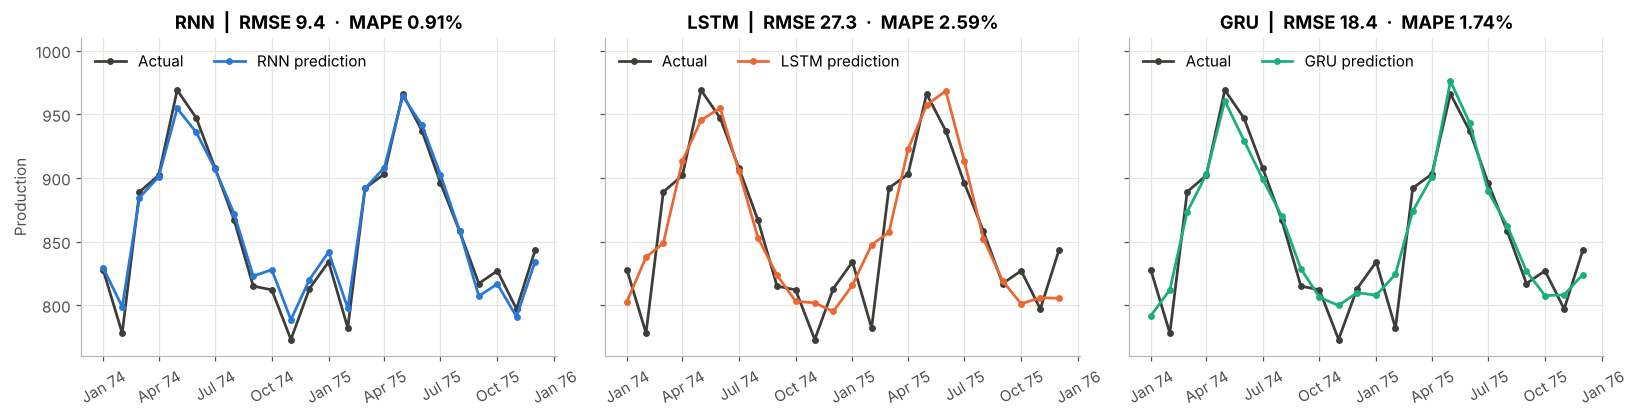

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, kind in zip(axes, ("RNN", "LSTM", "GRU")):
    ax.plot(test_index, y_test_true, color=COLORS["Actual"], marker="o", ms=3.5, label="Actual")
    ax.plot(test_index, preds_onestep[kind], color=COLORS[kind], marker="o", ms=3.5, label=f"{kind} prediction")
    r = results[kind]
    ax.set_title(f"{kind}  |  RMSE {r['RMSE (1-step)']:.1f}  ·  MAPE {r['MAPE (%) (1-step)']:.2f}%")
    ax.set_ylim(760, 1010)                                   # head-room so the legend never covers the lines
    ax.legend(loc="upper left", ncol=2)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Production")
plt.tight_layout(); plt.show()

## 4.2 12-month recursive back-test (1974)

The harder test: predict the whole of 1974 from data up to Dec 1973 only.

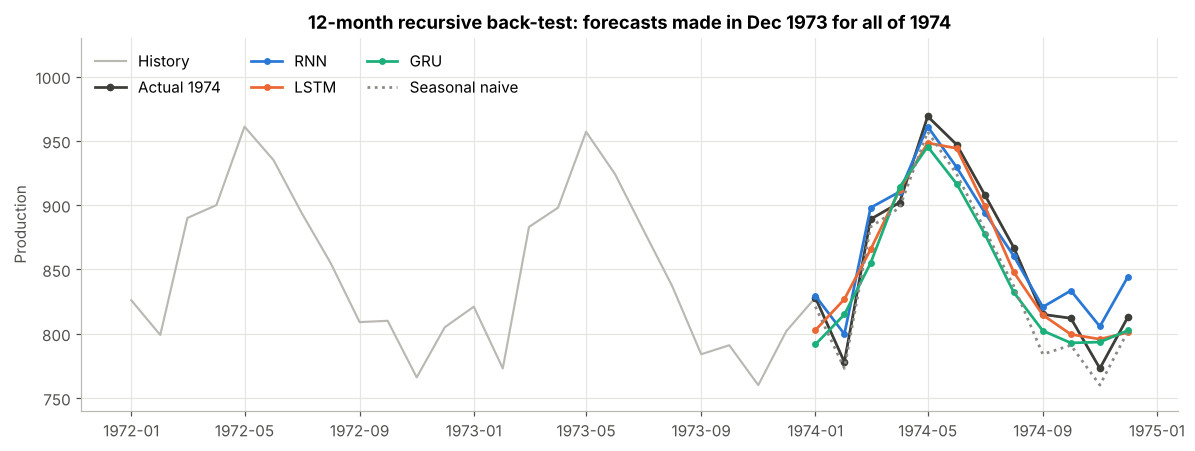

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.2))
bt_index = test_index[:12]
ax.plot(series.index[-48:-12], series.values[-48:-12], color="#b9b8b3", lw=1.4, label="History")
ax.plot(bt_index, y_test_true[:12], color=COLORS["Actual"], marker="o", ms=4, label="Actual 1974")
for kind in ("RNN", "LSTM", "GRU"):
    ax.plot(bt_index, preds_backtest[kind], color=COLORS[kind], marker="o", ms=3.5, label=f"{kind}")
ax.plot(bt_index, preds_backtest["Baseline"], color=COLORS["Baseline"], ls=":", label="Seasonal naive")
ax.set_title("12-month recursive back-test: forecasts made in Dec 1973 for all of 1974")
ax.set_ylabel("Production"); ax.set_ylim(740, 1030); ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

## 4.3 Model comparison: RMSE, MAE, MAPE

,Val RMSE (tuning),RMSE (1-step),MAE (1-step),MAPE (%) (1-step),RMSE (12M),MAE (12M),MAPE (%) (12M)
RNN,10.37,9.44,7.61,0.91,17.72,14.80,1.77
LSTM,24.41,27.28,21.85,2.59,21.15,17.21,2.06
GRU,17.98,18.38,14.56,1.74,26.91,25.15,2.93
Seasonal naive,NaN,16.10,12.88,1.51,18.53,15.83,1.84


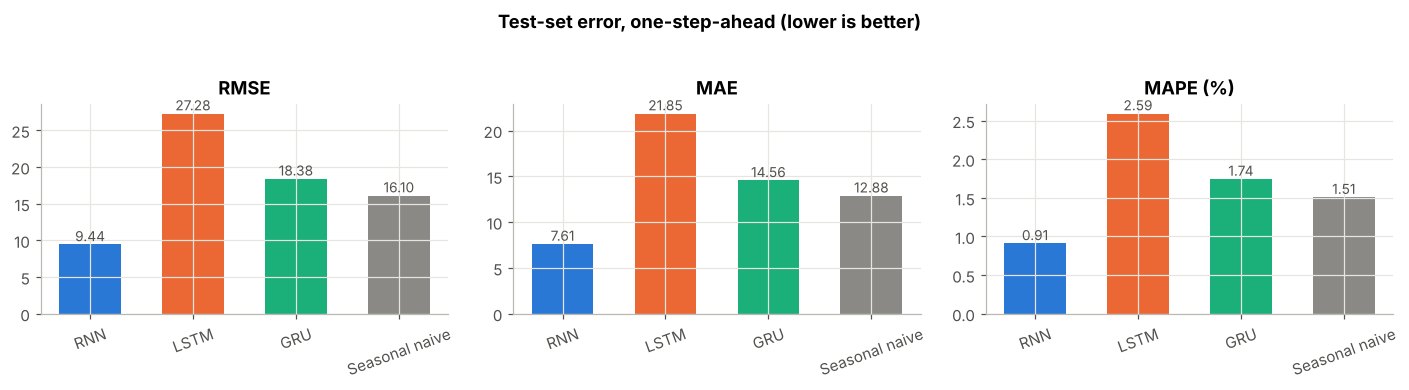

Best architecture on validation data -> RNN
Best architecture on the test set    -> RNN  (confirms the choice: True)


In [20]:
display(comparison.round(2))

# Visual comparison of the three headline metrics (one-step-ahead, test set)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
order = ["RNN", "LSTM", "GRU", "Seasonal naive"]
bar_colors = [COLORS["RNN"], COLORS["LSTM"], COLORS["GRU"], COLORS["Baseline"]]
for ax, metric in zip(axes, ["RMSE (1-step)", "MAE (1-step)", "MAPE (%) (1-step)"]):
    vals = comparison.loc[order, metric]
    ax.bar(order, vals, color=bar_colors, width=0.6)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color="#52514e")
    ax.set_title(metric.replace(" (1-step)", "")); ax.tick_params(axis="x", rotation=20)
plt.suptitle("Test-set error, one-step-ahead (lower is better)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

# The final forecasting model is chosen on VALIDATION RMSE (the test set is never used for selection)
winner = comparison.loc[["RNN", "LSTM", "GRU"], "Val RMSE (tuning)"].idxmin()
test_winner = comparison.loc[["RNN", "LSTM", "GRU"], "RMSE (1-step)"].idxmin()
print(f"Best architecture on validation data -> {winner}")
print(f"Best architecture on the test set    -> {test_winner}  (confirms the choice: {winner == test_winner})")

### 📌 Evaluation findings

| Test set (24 months) | RMSE | MAE | MAPE |
|---|:--:|:--:|:--:|
| **Simple RNN** | **9.44** | **7.61** | **0.91 %** |
| GRU | 18.38 | 14.56 | 1.74 % |
| LSTM | 27.28 | 21.85 | 2.59 % |
| Seasonal naive (baseline) | 16.10 | 12.88 | 1.51 % |

*One-step-ahead forecasts, original production units.*

- The **Simple RNN is the best model** both on the validation data (used for selection) and on the untouched test data: its average error is **under 1 %** and it is almost twice as accurate as the seasonal-naive baseline.
- **GRU** (1.74 %) is roughly on par with the naive baseline and **LSTM** (2.59 %) is worse than it. With only ~100-140 training windows, the extra gates and parameters of LSTM/GRU do not pay off, whereas the pattern here is simple (*same month last year + trend*) and a plain RNN captures it well.
- **Recursive 12-month back-test (1974):** errors grow because each prediction is fed back as input. The RNN still leads (RMSE 17.7, MAPE 1.77 %), but its edge over the seasonal-naive baseline (18.5, 1.84 %) is **small**; GRU (2.93 %) falls behind the baseline. Multi-month forecasts should therefore be treated with more caution than next-month forecasts.
- **Caveats:** the test set contains only 24 points and results of small neural networks vary with the random seed, so the *ranking* is indicative rather than definitive. All results here are fully reproducible (fixed seeds).

---
# 5 · Forecast: the next 12 months (Jan 1976 – Dec 1976)

## 5.1 Final model

For the production forecast we use the **architecture with the lowest validation RMSE and its tuned hyper-parameters**, now **re-trained on all 168 months** (so the most recent information is used). Because there is no validation data left, the number of epochs is fixed to the early-stopped value found during tuning.

To quantify uncertainty we combine two ingredients:

1. an **ensemble of 10 networks** trained with different random seeds (captures model/initialisation uncertainty), and
2. **residual simulation**: forecasts are repeated 1,000 times per network, adding at every step a random error drawn from the model's *out-of-sample* one-step errors (validation + test). Errors therefore **accumulate realistically** as the forecast moves further into the future.

The **95 % interval** is the 2.5th – 97.5th percentile of all simulated paths.

In [21]:
cfg = best[winner]
W, UNITS, BATCH, EPOCHS = cfg["window"], cfg["units"], cfg["batch"], cfg["best_epoch"]
print(f"Final model: {winner} | window={W}, units={UNITS}, batch={BATCH}, epochs={EPOCHS}")

# ---- Refit the scaler and the network on ALL data ----------------------------------------
scaler_full = MinMaxScaler().fit(series.values.reshape(-1, 1))
scaled_full = scaler_full.transform(series.values.reshape(-1, 1)).ravel()
X_all, y_all = make_sequences(scaled_full, W, W, N)

N_MODELS = 10
ensemble = []
for i in range(N_MODELS):
    tf.keras.utils.set_random_seed(SEED + i)
    m = build_model(winner, W, UNITS)
    m.fit(X_all, y_all, epochs=EPOCHS, batch_size=BATCH, shuffle=False, verbose=0)
    ensemble.append(m)
print(f"Trained {N_MODELS} {winner} networks on {len(X_all)} windows each.")

Final model: RNN | window=24, units=64, batch=8, epochs=101


Trained 10 RNN networks on 144 windows each.


In [22]:
HORIZON, N_SIMS = 12, 1000
future_index = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1), periods=HORIZON, freq="MS")
last_window  = series.values[-W:]                         # most recent W months (original units)

# ---- Out-of-sample one-step residuals of the evaluated winner (validation + test) -------------
*_, X_va_w, y_va_w, X_te_w, y_te_w = get_splits(W)
res_val  = inverse(y_va_w) - inverse(cfg["model"].predict(X_va_w, verbose=0).ravel())
res_test = inverse(y_te_w) - inverse(cfg["model"].predict(X_te_w, verbose=0).ravel())
residuals = np.concatenate([res_val, res_test])
residuals = residuals - residuals.mean()                  # centre so the noise adds no bias
print(f"Residual std used for the simulation: {residuals.std():.1f}")

def to_scaled(a):  return scaler_full.transform(a.reshape(-1, 1)).reshape(a.shape)
def to_orig(a):    return scaler_full.inverse_transform(a.reshape(-1, 1)).reshape(a.shape)

def forecast_paths(model, noise, rng):
    # Recursive forecast for many paths at once; noise=True adds resampled residual errors.
    n = N_SIMS if noise else 1
    windows = np.tile(last_window, (n, 1))                # (n, W) in original units
    out = np.zeros((n, HORIZON))
    for h in range(HORIZON):
        x = to_scaled(windows).reshape(n, W, 1)
        p = to_orig(model(x, training=False).numpy().ravel())
        if noise:
            p = p + rng.choice(residuals, size=n)
        out[:, h] = p
        windows = np.hstack([windows[:, 1:], p[:, None]])
    return out

rng = np.random.default_rng(SEED)
point_paths = np.vstack([forecast_paths(m, False, rng) for m in ensemble])    # (10, 12) noise-free
sim_paths   = np.vstack([forecast_paths(m, True,  rng) for m in ensemble])    # (10000, 12) with noise

forecast = pd.DataFrame({
    "Forecast": point_paths.mean(axis=0),
    "Lower 95%": np.percentile(sim_paths, 2.5, axis=0),
    "Upper 95%": np.percentile(sim_paths, 97.5, axis=0),
}, index=future_index)
forecast.index.name = "Month"

Residual std used for the simulation: 9.9


## 5.2 Forecast visualisation

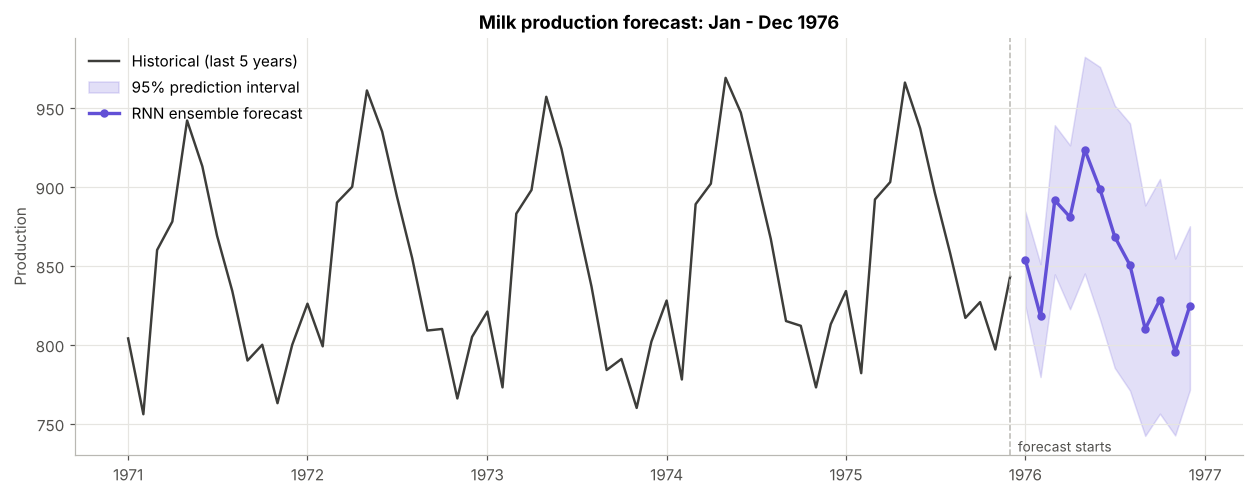

,Forecast,Lower 95%,Upper 95%
Month,,,
Jan 1976,853.90,824.70,884.40
Feb 1976,818.20,779.50,851.00
Mar 1976,891.40,844.50,939.00
Apr 1976,880.80,822.50,926.30
May 1976,923.50,845.10,982.30
Jun 1976,898.50,816.10,975.90
Jul 1976,868.40,785.30,951.50
Aug 1976,850.50,771.00,940.10
Sep 1976,810.00,742.30,888.30


In [23]:
fig, ax = plt.subplots(figsize=(11.5, 4.6))
hist_tail = series.iloc[-60:]
ax.plot(hist_tail.index, hist_tail.values, color=COLORS["Actual"], lw=1.6, label="Historical (last 5 years)")
ax.fill_between(forecast.index, forecast["Lower 95%"], forecast["Upper 95%"],
                color=COLORS["Forecast"], alpha=0.18, label="95% prediction interval")
ax.plot(forecast.index, forecast["Forecast"], color=COLORS["Forecast"], marker="o", ms=4.5, lw=2.2,
        label=f"{winner} ensemble forecast")
ax.axvline(series.index[-1], color="#b9b8b3", lw=1, ls="--")
ax.text(series.index[-1], ax.get_ylim()[0], "  forecast starts", color="#52514e", fontsize=9, va="bottom")
ax.set_title("Milk production forecast: Jan - Dec 1976")
ax.set_ylabel("Production"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

display(forecast.round(1).assign(Month=lambda d: d.index.strftime("%b %Y")).set_index("Month"))

## 5.3 Sanity check: forecast vs the last 12 months

A good forecast should preserve the seasonal shape and continue the (now slow) trend. We compare it with 1975 month by month.

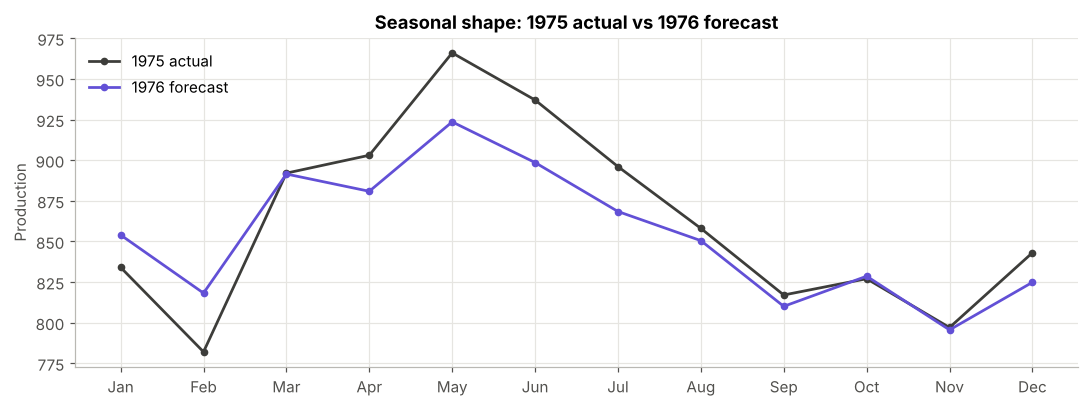

,1975 actual,1976 forecast,Change (%)
Jan,834.00,853.90,2.40
Feb,782.00,818.20,4.60
Mar,892.00,891.40,-0.10
Apr,903.00,880.80,-2.50
May,966.00,923.50,-4.40
Jun,937.00,898.50,-4.10
Jul,896.00,868.40,-3.10
Aug,858.00,850.50,-0.90
Sep,817.00,810.00,-0.90
Oct,827.00,828.60,0.20


Total 1975 (actual)    : 10,352
Total 1976 (forecast)  : 10,244  (-1.0% vs 1975)
Peak forecast month    : May 1976 (924)
Lowest forecast month  : Nov 1976 (796)
Average interval width : +/- 61 units (about 7.2% of the forecast)


In [24]:
last12 = series.iloc[-12:]
cmp12 = pd.DataFrame({"1975 actual": last12.values, "1976 forecast": forecast["Forecast"].values},
                     index=[d.strftime("%b") for d in future_index])
cmp12["Change (%)"] = (cmp12["1976 forecast"] / cmp12["1975 actual"] - 1) * 100

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(cmp12.index, cmp12["1975 actual"],   color=COLORS["Actual"],   marker="o", ms=4, label="1975 actual")
ax.plot(cmp12.index, cmp12["1976 forecast"], color=COLORS["Forecast"], marker="o", ms=4, label="1976 forecast")
ax.set_title("Seasonal shape: 1975 actual vs 1976 forecast"); ax.set_ylabel("Production"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
display(cmp12.round(1))
print(f"Total 1975 (actual)    : {last12.sum():,.0f}")
print(f"Total 1976 (forecast)  : {forecast['Forecast'].sum():,.0f}  ({(forecast['Forecast'].sum() / last12.sum() - 1) * 100:+.1f}% vs 1975)")
print(f"Peak forecast month    : {forecast['Forecast'].idxmax():%b %Y} ({forecast['Forecast'].max():.0f})")
print(f"Lowest forecast month  : {forecast['Forecast'].idxmin():%b %Y} ({forecast['Forecast'].min():.0f})")
print(f"Average interval width : +/- {((forecast['Upper 95%'] - forecast['Lower 95%']) / 2).mean():.0f} units (about {((forecast['Upper 95%'] - forecast['Lower 95%']) / 2 / forecast['Forecast']).mean() * 100:.1f}% of the forecast)")

---
# 6 · Business Insights and Recommendations

### What the forecast says (Jan – Dec 1976)

- **Total 1976 production ≈ 10,244 units, about 1 % below 1975 (10,352)** – i.e. the business should plan for a **flat market-volume year**, consistent with growth having levelled off since 1972.
- The **seasonal shape stays the same**: peak in **May (≈924)**, trough in **November (≈796)**, and a dip in **February (≈818)**. The gap between peak and trough is about **16 %**.
- **Uncertainty:** the 95 % interval is roughly **±30 units in January and widens to ±80 by mid-year (average ±61, ≈7 %)**. Near-term months are much more reliable than later ones.

### Recommendations

| Area | How to use the forecast |
|---|---|
| **Supply chain & distribution** | Contract transport, cold-chain and processing capacity for the **March – July high season** (forecast ≥ 868 per month, peaking in May) and scale it back from August. Use the lower bound for committed volumes and the upper bound for "burst" capacity. |
| **Inventory & storage** | Build storage / processing buffers ahead of the **April – June** peak and release them in the autumn trough. Plan shelf-life-sensitive products (fresh milk) against the base forecast, and storable products (butter, powder) against the surplus months. |
| **Workforce & operations** | Roster seasonal and overtime labour for **spring**, schedule maintenance, leave and training in **Sep – Nov** (lowest output, ≈ 796 – 829). |
| **Strategic decisions** | Volume growth has plateaued, so further expansion should come from **smoothing the seasonal swing** (e.g. feeding / calving-schedule management to lift autumn output) or from value-added products, rather than assuming trend growth. |
| **Monitoring** | **Refresh the model every month** with the latest actuals (one-step-ahead error is < 1 %), track actual-vs-forecast, and re-train if actuals repeatedly fall outside the 95 % band. |

---
## ✅ Conclusion

- The data are clean and dominated by a **strong trend and a stable 12-month seasonal cycle**.
- Three recurrent networks (**RNN, LSTM, GRU**) were built, tuned by grid search (window, units, batch size, early-stopped epochs) and compared with RMSE, MAE and MAPE against a seasonal-naive baseline.
- The **Simple RNN (24-month window, 64 units)** was the best model (**test MAPE 0.91 %**, RMSE 9.4) and was used to forecast the next 12 months with a 95 % prediction interval.
- **Limitations:** short history (168 points), univariate input (no weather, feed or price information), and multi-step forecasts are less accurate than next-month forecasts. Adding external drivers and re-training regularly are the natural next steps.